# Лаба 2. Символ Лежандра через символ Якоби

Квадратное сравнение $x^2 \equiv a \pmod p$ при простом нечётном $p$ и $(a,p)=1$ разрешимо тогда и только тогда, когда символ Лежандра $\left(\frac{a}{p}\right)=1$.

Прямое вычисление по Гауссу требует **факторизации** числа $b$. Символ Якоби обобщает символ Лежандра на составные нечётные $n$ и обладает теми же свойствами (включая закон взаимности), поэтому факторизация не нужна. Трудоёмкость $O(\log^2 n)$.

In [1]:
import importlib, glob, os, subprocess, sys

REPO_URL = "https://github.com/KseniaKov/methods-programming_lab.git"   # пусто = сразу загрузить файл вручную
MODULE = "legendre_jacobi"

try:
    importlib.import_module(MODULE)
except ModuleNotFoundError:
    found = False
    if REPO_URL:
        try:
            subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
            paths = glob.glob(f"repo/**/{MODULE}.py", recursive=True)
            if paths:
                sys.path.append(os.path.dirname(os.path.abspath(paths[0])))
                found = True
        except (subprocess.CalledProcessError, FileNotFoundError):
            print("Не удалось клонировать репозиторий")
    if not found:
        from google.colab import files
        print(f"Выберите файл {MODULE}.py с компьютера")
        files.upload()
    importlib.invalidate_caches()
    importlib.import_module(MODULE)
print(f"{MODULE}.py найден")

legendre_jacobi.py найден


In [2]:
import random, time
import matplotlib.pyplot as plt
from legendre_jacobi import (jacobi, legendre, legendre_euler, legendre_gauss,
                             legendre_factorization, num_solutions, is_probable_prime)

## 1. Пошаговый пример
Вычислим $\left(\frac{1001}{9907}\right)$. Функция `jacobi` умеет записывать шаги алгоритма (шаги 1–4 из методички).

In [3]:
steps = []
value = jacobi(1001, 9907, steps)
print("\n".join(steps))
print()
print("(1001/9907) =", value)
print("критерий Эйлера:", legendre_euler(1001, 9907))

вычисляем (1001/9907)
шаг 4: (1001/9907) = (898/1001) * (1)
шаг 1: (898/1001) = (-103/1001)
шаг 3: (-1/1001) = 1
шаг 4: (103/1001) = (74/103) * (1)
шаг 1: (74/103) = (-29/103)
шаг 3: (-1/103) = -1
шаг 4: (29/103) = (16/29) * (1)
шаг 1: (16/29) = (-13/29)
шаг 3: (-1/29) = 1
шаг 4: (13/29) = (3/13) * (1)
шаг 4: (3/13) = (1/3) * (1)
c = 1, (1/3) = 1; результат -1

(1001/9907) = -1
критерий Эйлера: -1


## 2. Все символы Лежандра для малого простого
Для $p=11$ сравним значения алгоритма с реальным перебором квадратов.

In [4]:
p = 11
squares = sorted({x * x % p for x in range(1, p)})
print("квадраты по модулю", p, ":", squares)
print()
print(" a | (a/p) | вычет? | решений x^2=a")
for a in range(p):
    print(f"{a:2d} | {legendre(a, p):5d} | {str(a in squares):6s} | {num_solutions(a, p)}")

квадраты по модулю 11 : [1, 3, 4, 5, 9]

 a | (a/p) | вычет? | решений x^2=a
 0 |     0 | False  | 1
 1 |     1 | True   | 2
 2 |    -1 | False  | 0
 3 |     1 | True   | 2
 4 |     1 | True   | 2
 5 |     1 | True   | 2
 6 |    -1 | False  | 0
 7 |    -1 | False  | 0
 8 |    -1 | False  | 0
 9 |     1 | True   | 2
10 |    -1 | False  | 0


## 3. Три способа дают один результат
Алгоритм через символ Якоби сравнивается с критерием Эйлера, критерием Гаусса и первым алгоритмом методички (с факторизацией).

In [5]:
rnd = random.Random(1)
primes = [q for q in range(10**4, 10**4 + 3000) if is_probable_prime(q)]
checked = 0
for _ in range(2000):
    p_, a_ = rnd.choice(primes), rnd.randrange(-10**6, 10**6)
    v = legendre(a_, p_)
    assert v == legendre_euler(a_, p_) == legendre_factorization(a_, p_)
    checked += 1
for p_ in (101, 211, 307, 401):                       # критерий Гаусса работает за O(p)
    for a_ in range(-p_, 2 * p_):
        assert legendre(a_, p_) == legendre_gauss(a_, p_)
        checked += 1
print("Проверено значений:", checked, "- все совпали")

Проверено значений: 5060 - все совпали


## 4. Свойства символа Якоби
Проверим свойства из теоремы на случайных нечётных $a, b$: мультипликативность, периодичность, закон взаимности, а также $\left(\frac{-1}{b}\right)$ и $\left(\frac{2}{b}\right)$.

In [6]:
from math import gcd
rnd = random.Random(2)
for _ in range(2000):
    a, c, b = rnd.randrange(10**9), rnd.randrange(10**9), rnd.randrange(3, 10**9, 2)
    assert jacobi(a * c, b) == jacobi(a, b) * jacobi(c, b)              # 2) по верхнему аргументу
    assert jacobi(a, b) == jacobi(a + 5 * b, b)                         # 1) a = c (mod b)
    assert jacobi(-1, b) == (-1) ** ((b - 1) // 2)                      # 4)
    assert jacobi(2, b) == (-1) ** ((b * b - 1) // 8)                   # 5)
    x, y = rnd.randrange(3, 10**9, 2), rnd.randrange(3, 10**9, 2)
    if gcd(x, y) == 1:                                                  # 6) закон взаимности
        assert jacobi(x, y) == jacobi(y, x) * (-1) ** ((x - 1) // 2 * ((y - 1) // 2))
    d = rnd.randrange(3, 10**4, 2)
    assert jacobi(a, b * d) == jacobi(a, b) * jacobi(a, d)              # 3) по нижнему аргументу
print("Все свойства выполнены")

Все свойства выполнены


## 5. Замечание из методички: символ Якоби = 1 не значит, что корень существует
Для составного $n$ равенство $\left(\frac{a}{n}\right)=1$ ещё не означает, что $x^2\equiv a \pmod n$ разрешимо. Поэтому в `legendre` по умолчанию проверяется, что $p$ простое.

In [7]:
n, a = 15, 2
print(f"({a}/{n}) =", jacobi(a, n))
print("решения x^2 = 2 (mod 15):", [x for x in range(n) if (x * x - a) % n == 0])

try:
    legendre(2, 15)
except ValueError as e:
    print("legendre(2, 15):", e)

(2/15) = 1
решения x^2 = 2 (mod 15): []
legendre(2, 15): p не является простым числом


## 6. Большие числа
Простые числа Мерсенна $2^{127}-1$, $2^{521}-1$, $2^{607}-1$ и случайные $a$ той же длины. Результат сверяется с критерием Эйлера (через встроенное `pow`).

In [8]:
rnd = random.Random(3)
for k in (127, 521, 607):
    p_ = 2**k - 1
    a_ = rnd.getrandbits(k)
    t = time.perf_counter(); v = legendre(a_, p_, check_prime=False); dt = time.perf_counter() - t
    print(f"p = 2^{k}-1: (a/p) = {v:2d}, время {dt*1000:.2f} мс, совпадает с Эйлером: {v == legendre_euler(a_, p_)}")

p = 2^127-1: (a/p) =  1, время 0.03 мс, совпадает с Эйлером: True
p = 2^521-1: (a/p) =  1, время 0.12 мс, совпадает с Эйлером: True
p = 2^607-1: (a/p) =  1, время 0.15 мс, совпадает с Эйлером: True


## 7. Сложность
**Якоби и факторизация.** Первый алгоритм методички тратит основное время на разложение $b$ на множители (пробные деления — $O(\sqrt b)$, то есть экспонента от длины $p$).
Алгоритм через символ Якоби растёт полиномиально.

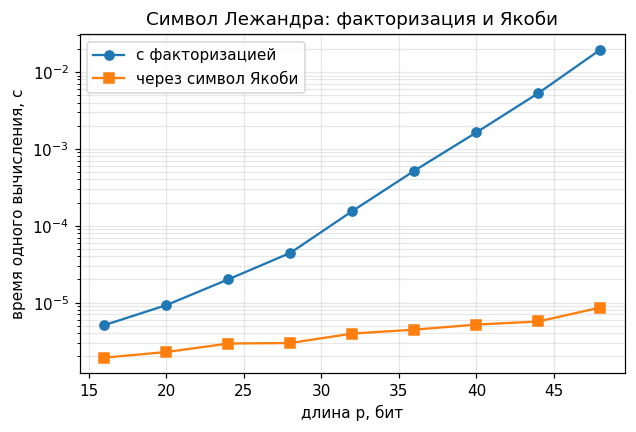

In [9]:
def random_prime(bits, rnd):
    while True:
        q = rnd.getrandbits(bits) | (1 << (bits - 1)) | 1
        if is_probable_prime(q):
            return q

rnd = random.Random(10)
bits_list = [16, 20, 24, 28, 32, 36, 40, 44, 48]
t_fact, t_jac = [], []
for bits in bits_list:
    p_ = random_prime(bits, rnd)
    sample = [rnd.randrange(1, p_) for _ in range(100)]
    t = time.perf_counter()
    for a_ in sample: legendre_factorization(a_, p_)
    t_fact.append((time.perf_counter() - t) / len(sample))
    t = time.perf_counter()
    for a_ in sample: jacobi(a_, p_)
    t_jac.append((time.perf_counter() - t) / len(sample))

plt.figure(figsize=(6.4, 4))
plt.semilogy(bits_list, t_fact, "o-", label="с факторизацией")
plt.semilogy(bits_list, t_jac, "s-", label="через символ Якоби")
plt.xlabel("длина p, бит"); plt.ylabel("время одного вычисления, с")
plt.title("Символ Лежандра: факторизация и Якоби"); plt.legend(); plt.grid(alpha=.3, which="both")
plt.show()

**Рост от длины числа.** Для Якоби число итераций $O(\log n)$, каждая стоит не больше $O(\log n)$, итого $O(\log^2 n)$. Это оценка сверху: на графике в логарифмических осях время не должно расти круче прямой $\propto n^2$. Наклон может быть ниже, потому что в Python операции с длинными числами выполняются быстрее учебной модели «по цифрам».

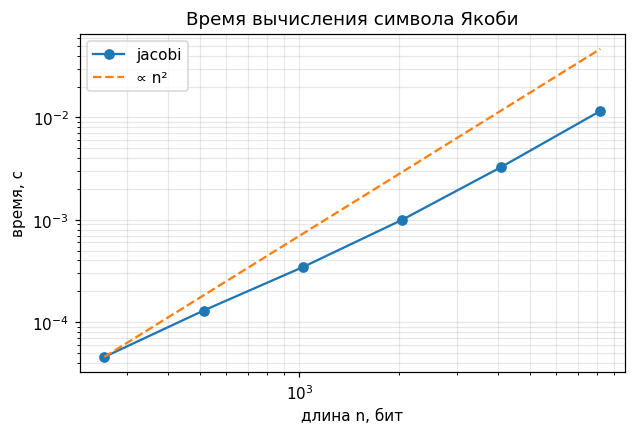

In [10]:
rnd = random.Random(11)
bits_list = [256, 512, 1024, 2048, 4096, 8192]
times = []
for bits in bits_list:
    n_ = rnd.getrandbits(bits) | (1 << (bits - 1)) | 1
    a_ = rnd.getrandbits(bits)
    reps = 20
    t = time.perf_counter()
    for _ in range(reps): jacobi(a_, n_)
    times.append((time.perf_counter() - t) / reps)

plt.figure(figsize=(6.4, 4))
plt.loglog(bits_list, times, "o-", label="jacobi")
plt.loglog(bits_list, [times[0] * (b / bits_list[0]) ** 2 for b in bits_list], "--", label="∝ n²")
plt.xlabel("длина n, бит"); plt.ylabel("время, с")
plt.title("Время вычисления символа Якоби"); plt.legend(); plt.grid(alpha=.3, which="both")
plt.show()

## Вывод

* Алгоритм через символ Якоби совпадает с критерием Эйлера, критерием Гаусса и определением (перебором квадратов) на всех проверенных данных.
* Он не требует факторизации и работает за $O(\log^2 n)$, а вариант с факторизацией быстро становится непригодным с ростом $p$.
* Символ Якоби равен символу Лежандра только для простого модуля; для составного $n$ значение $1$ не гарантирует разрешимости сравнения.